# Bibliotecas

In [1]:
import sys
sys.path.append("..")

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt

from random import shuffle
from matplotlib.ticker import MultipleLocator, FuncFormatter

from src.perceptron import Perceptron, ActivationFunction
from src.utils import pi_fraction_formatter, make_features, my_activation_function
from src.optimizers import SGD, Adam, AdamW

# Entrada

### Série de Taylor

A série de Taylor representa uma função por meio de um polinômio construído a partir de suas derivadas em torno de um ponto $a$:

$$
f(x) = \sum_{n=0}^{\infty}
\frac{f^{(n)}(a)}{n!}(x-a)^n
$$

Considerando apenas os termos até o grau $d$, obtemos uma aproximação polinomial:

$$
f(x) \approx \sum_{n=0}^{d}
\frac{f^{(n)}(a)}{n!}(x-a)^n
$$

Para a função cosseno, a série de Taylor em torno de $a=\pi$ é:

$$
\cos(x) \approx -1+\frac{(x-\pi)^2}{2!}
-\frac{(x-\pi)^4}{4!}
+\frac{(x-\pi)^6}{6!}
$$

In [3]:
rng = np.random.default_rng(42) # cria um gerador aleatório com semente fixa

# gera 500 entradas de treino igualmente espaçadas em [0, 2π]
x_train = np.linspace(0, 2*np.pi, 500)

# gera 200 entradas de teste aleatórias em [0, 2π)
x_test  = rng.uniform(0, 2*np.pi, 200)

# calcula as saídas desejadas: y = cos(x)
y_train, y_test = np.cos(x_train), np.cos(x_test)

### Normalização e expansão polinomial

As entradas são centralizadas em torno de $\pi$ e normalizadas para o intervalo $[-1,1]$:

$$
t = \frac{x-\pi}{\pi}
$$

Em seguida, cada entrada é representada por um vetor de features polinomiais de grau $d$:

$$
\phi(x) = [1,t,t^2,\ldots,t^d]
$$

In [4]:
# grau do polinômio usado para gerar as features
degree = 6 

In [5]:
# expande as entradas em features polinomiais de grau 6
X_train = make_features(x_train, degree)
X_test  = make_features(x_test,  degree)

print(x_train[0:6])
print(X_test[0])
print(y_test[0:6])

[0.         0.01259155 0.02518311 0.03777466 0.05036621 0.06295777]
[1.         0.30020767 0.09012464 0.02705611]
[ 0.14995256 -0.92715926  0.63061148 -0.3247018   0.82997485  0.9882925 ]


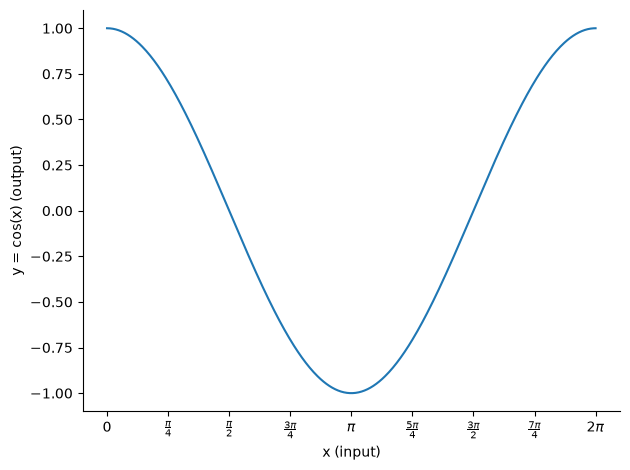

In [6]:
# plota a função cosseno no conjunto de treino
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4)) 
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train)
ax.set_xlabel("x (input)")
ax.set_ylabel("y = cos(x) (output)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Função de ativação

In [7]:
my_act_function = ActivationFunction(my_activation_function)

# Treinamento

### Função de perda

O erro do modelo é avaliado pelo erro quadrático médio (*Mean Squared Error* — MSE):

$$
\mathrm{MSE} =
\frac{1}{N}\sum_{i=1}^{N}
\left(y_i-\hat{y}_i\right)^2
$$

Durante o treinamento, os pesos são atualizados para minimizar esse erro.

In [8]:
def train(optimizer, n_epochs=4500, seed=42):
    np.random.seed(seed) # fixa a semente para a inicialização dos pesos
    random.seed(seed) # fixa a semente para o embaralhamento das amostras

    # inicializa o perceptron 
    p = Perceptron(my_act_function, X_train.shape[1], 1, optimizer)

    idx = list(range(len(y_train))) # índices das amostras de treino
    mse_epoch = [] # armazena o erro quadrático médio por época

    for _ in range(n_epochs):
        shuffle(idx) # embaralha a ordem das amostras a cada época

        for k in idx:
            # calcula a saída estimada e atualiza os pesos com base no erro
            y_e = p.output(X_train[k])
            p.learn([y_train[k]], y_e, X_train[k])

        # calcula as previsões para todas as amostras de treino
        pred = X_train @ p.synaptic_weights[0]

        # MSE = média dos erros quadráticos na época
        mse_epoch.append(np.mean((y_train - pred)**2))
        
    return p, mse_epoch

### Otimizador AdamW

O AdamW adapta as atualizações dos parâmetros com base em médias móveis do gradiente e de seu quadrado, além de aplicar decaimento dos parâmetros (*weight decay*):

$$
\mathbf{x}_k =
\mathbf{x}_{k-1}
-\eta\frac{\hat{\mathbf{m}}_k}
{\sqrt{\hat{\mathbf{v}}_k}+\varepsilon}
-\eta\lambda\mathbf{x}_{k-1}
$$

Em que $\eta$ é a taxa de aprendizagem, $\hat{\mathbf{m}}_k$ e $\hat{\mathbf{v}}_k$ são os momentos corrigidos, $\varepsilon$ evita a divisão por zero e $\lambda$ controla o decaimento dos parâmetros.

In [9]:
p_adamw, mse_adamw = train(AdamW(eta=0.0001, lam=1e-4))

# Resultados

## Gráfico do erro por época

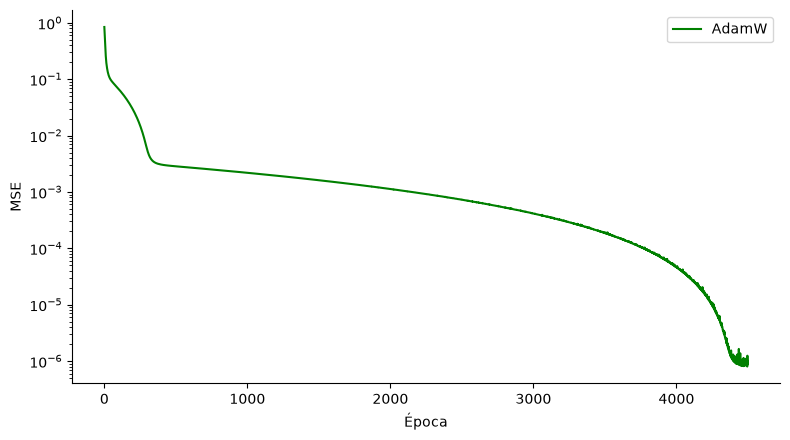

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(mse_adamw, color="green",label="AdamW")

ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Comparação da saída

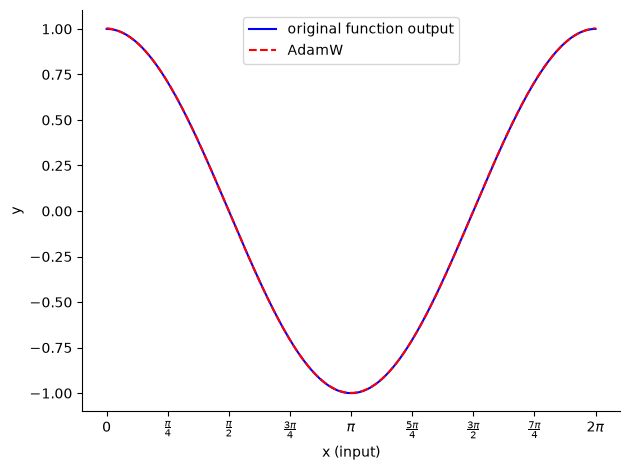

In [11]:
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4))
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train, color="blue", label = "original function output")

# plota as previsões do modelo treinado com AdamW
for name, p in [("AdamW", p_adamw)]:
    ax.plot(x_train, X_train @ p.synaptic_weights[0], "--", color="red", label=name)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("x (input)")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.show()

## MSE no teste

In [12]:
# erro quadratico médio (MSE) no conjunto de teste
mse_test = np.mean((y_test - X_test @ p.synaptic_weights[0])**2)
print(f"MSE no conjunto de teste: {mse_test}")

MSE no conjunto de teste: 7.816664468292866e-07


# Comparação dos métodos

### Gradiente descendente estocástico (SGD)

O SGD atualiza os pesos na direção oposta ao gradiente da função de perda:

$$
\mathbf{x}_k =
\mathbf{x}_{k-1} - \eta \nabla f(\mathbf{x}_{k-1})
$$

Em que $\eta$ é a taxa de aprendizagem e $\nabla f$ é o gradiente da função de perda.

In [13]:
p_sgd, mse_sgd = train(SGD(eta=0.005))

### Adam (*Adaptive Moment Estimation*)

O Adam combina médias móveis do gradiente e de seu quadrado para adaptar as atualizações dos pesos:

$$
\mathbf{m}_k =
\beta_1 \mathbf{m}_{k-1} + (1-\beta_1)\nabla f(\mathbf{x}_{k-1})
$$

$$
\mathbf{v}_k =
\beta_2 \mathbf{v}_{k-1} + (1-\beta_2) \nabla^2 f(\mathbf{x}_{k-1})
$$

Os momentos são corrigidos para reduzir o viés inicial:

$$
\hat{\mathbf{m}}_k =
\frac{\mathbf{m}_k}{1-\beta_1^k},
\qquad
\hat{\mathbf{v}}_k =
\frac{\mathbf{v}_k}{1-\beta_2^k}
$$

A atualização dos parâmetros é dada por:

$$
\mathbf{x}_k =
\mathbf{x}_{k-1} -
\eta \frac{\hat{\mathbf{m}}_k}
{\sqrt{\hat{\mathbf{v}}_k}+\varepsilon}
$$

Em que $\nabla f(\mathbf{x}_{k-1})$ é o gradiente da função de perda em relação aos parâmetros no passo anterior, $\beta_1$ e $\beta_2$ controlam as médias móveis, $\eta$ é a taxa de aprendizagem e $\varepsilon$ evita divisão por zero.

In [14]:
p_adam, mse_adam = train(Adam(eta=0.0001))

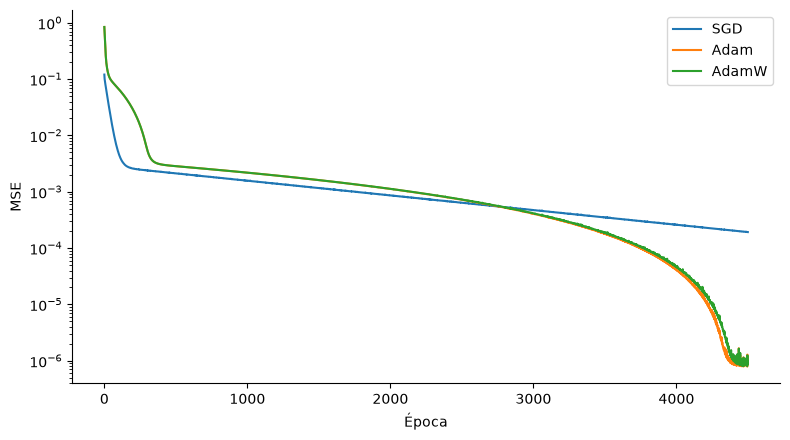

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(mse_sgd, label="SGD")
ax.plot(mse_adam, label="Adam")
ax.plot(mse_adamw, label="AdamW")

ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

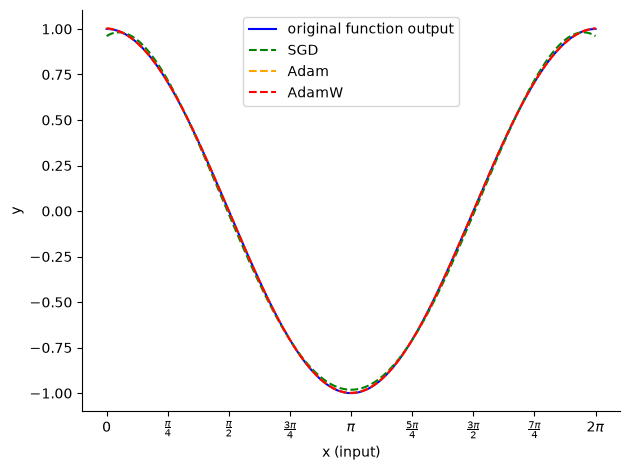

In [ ]:
colors = {"SGD": "green", "Adam": "orange", "AdamW": "red"}

ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4))
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train, color="blue", label = "original function output")

# plota as previsões do modelo treinado com SGD, Adam e AdamW
for name, p in [("SGD", p_sgd), ("Adam", p_adam), ("AdamW", p_adamw)]:
    ax.plot(x_train, X_train @ p.synaptic_weights[0], "--", color=colors[name], label=name)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("x (input)")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.show()

In [17]:
# erro quadratico médio (MSE) no conjunto de teste para cada otimizador
mse_sgd_test = np.mean((y_test - X_test @ p_sgd.synaptic_weights[0])**2)
mse_adam_test = np.mean((y_test - X_test @ p_adam.synaptic_weights[0])**2)
mse_adamw_test = np.mean((y_test - X_test @ p_adamw.synaptic_weights[0])**2)

print(f"MSE no conjunto de teste (SGD): {mse_sgd_test}")
print(f"MSE no conjunto de teste (Adam): {mse_adam_test}")
print(f"MSE no conjunto de teste (AdamW): {mse_adamw_test}")

MSE no conjunto de teste (SGD): 0.00017867547091581095
MSE no conjunto de teste (Adam): 7.621735248641616e-07
MSE no conjunto de teste (AdamW): 7.816664468292866e-07


### Conclusões do experimento

O Adam apresentou o menor erro no conjunto de teste, com MSE de $7{,}6217 \times 10^{-7}$, seguido pelo AdamW, com $7{,}8166 \times 10^{-7}$. Ambos obtiveram aproximações semelhantes, enquanto o SGD apresentou o erro de $1{,}7868 \times 10^{-4}$.

Quanto à velocidade de convergência, o Adam e o AdamW convergiram mais rápido que o SGD, pois adaptam as atualizações com base nos gradientes. Essa diferença pode ser observada nas curvas de erro ao longo das épocas. O decaimento dos pesos no AdamW também pode afetar a velocidade de convergência, o que acabou tornando ele mais lento em relação ao Adam.

O AdamW apresentou erro ligeiramente maior que o Adam, mas a diferença foi mínima. O decaimento dos pesos (*weight decay*) pode ajudar a reduzir o sobreajuste. Neste experimento, os resultados indicam que o decaimento praticamente não alterou a qualidade da aproximação no conjunto de teste.